<a href="https://colab.research.google.com/github/BWahot/Knowledge-Engineering/blob/main/Autonomous_Trailer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Knowledge Engineering**
**: Smart Traffic Light Navigation Agent**

****

*Adapted from [Zainabu Muti](https://www.linkedin.com/in/zainabu-muti-3789591b3/)* :)

**Step 1: Identify the Task**

The task is to help a self-driving trailer (a) choose the cheapest road route from **Nairobi to Kisumu** and (b) make safe driving decisions along the way (traffic lights, roadblocks, hazards).

**Goal:** Deliver cargo safely to Kisumu while minimising total distance, obeying traffic rules and avoiding accidents.

*(From our PEAS analysis: the environment is partially observable, stochastic, sequential, dynamic and multi-agent.)*
The task is to help a car decide what to do based on the traffic light color.

**Step 2: Assemble Relevant Knowledge**

The agent needs to know:
* The **towns** (nodes) and the **roads** between them with distances in km, taken from our Practical Exercise 3 directed graph and distance measures.
* The **traffic rules**: the correct action for each light colour (Red, Yellow, Green).
* The **hazard rules**: what to do at a roadblock, a flooded road or a pedestrian crossing.
* The **goal**: reach Kisumu at the lowest total distance.

**Sources:** Practical Exercise 3 (directed graph, search tree, route costs) and the Kenyan Highway Code. *No APIs or web scraping were used in this exercise.*

**Step 3: Define the Vocabulary**

* **Predicates** (represented in Python as dictionary entries and functions):
  * `Road(A, B, km)`: a road from town A to town B of length km
  * `Rule(condition, action)`: the action the trailer must take under a condition (e.g. a light colour)
  * `Route(path, cost)`: a path of towns and its total distance
  * `Better(R1, R2)`: R1 costs less than R2
* **Constants:**
  * Towns: Nairobi, Naivasha, Nakuru, Eldoret, Kericho, Kisumu, Thika, Nyeri
  * Conditions: Red, Yellow, Green, Roadblock, Flooding, PedestrianCrossing

**Step 4: Encode General Knowledge about the Domain** `[3 marks]`

`road_graph` encodes the facts `Road(A, B, km)`: each key is a town and each inner dictionary lists the towns reachable from it with the distance.
`rules` encodes `Rule(condition, action)`.


In [ ]:
# Road(A, B, km) facts, from the Practical Exercise 3 directed graph
road_graph = {
    "Nairobi":  {"Naivasha": 91, "Thika": 47},
    "Naivasha": {"Nakuru": 75},
    "Thika":    {"Nyeri": 113},
    "Nyeri":    {"Nakuru": 167},
    "Nakuru":   {"Eldoret": 160, "Kericho": 107},
    "Eldoret":  {"Kisumu": 125},
    "Kericho":  {"Kisumu": 80},
    "Kisumu":   {}
}

# Rule(condition, action) facts: traffic-light rules and hazard rules
rules = {
    "Red": "Stop: it is unsafe to move.",
    "Yellow": "Slow down and prepare to stop.",
    "Green": "Go: it is safe to proceed.",
    "Roadblock": "Stop, then reroute using an alternative road.",
    "Flooding": "Stop and reroute; do not cross flooded roads.",
    "PedestrianCrossing": "Slow down and give way to pedestrians."
}

print("Towns in KB:", list(road_graph.keys()))
print("Rules in KB:", len(rules))


Towns in KB: ['Nairobi', 'Naivasha', 'Thika', 'Nyeri', 'Nakuru', 'Eldoret', 'Kericho', 'Kisumu']
Rules in KB: 6


**Step 5: Add New Facts to the Knowledge Base** `[4 marks]`

In [ ]:
def show_kb():
    print("\n--- Current Knowledge Base ---")
    print("Roads:")
    for town, roads in road_graph.items():
        for dest, km in roads.items():
            print(f"{town:10} ➜ {dest:10} {km} km")
    print("\nRules:")
    for condition, action in rules.items():
        print(f"{condition:20} ➜ {action}")
    print("-------------------------------")

def add_new_fact(condition, action):
    """Add a new rule directly to the KB (- without user input)."""
    rules[condition.capitalize()] = action
    print(f"Added fact: '{condition.capitalize()}' ➜ '{action}'")

def add_new_road(a, b, km):
    """Add a new road directly to the KB (- without user input)."""
    road_graph.setdefault(a, {})[b] = km
    road_graph.setdefault(b, {})      # make sure the destination exists as a town
    print(f"Added fact: Road({a}, {b}, {km} km)")

# Example of adding facts
add_new_fact("Roadblock", "Stop, then reroute using an alternative road")
add_new_fact("Roadworks", "Slow down and follow the diversion")
add_new_road("Eldoret", "Kitale", 70)
add_new_road("Nakuru", "Kisumu", 190)

def add_fact():
    """Add new knowledge (facts) to the KB."""
    kind = input("Add a road or a rule? (road/rule): ").strip().lower()
    if kind == "road":
        a = input("From town: ").strip().capitalize()
        b = input("To town: ").strip().capitalize()
        km = int(input(f"Distance from {a} to {b} in km: "))
        road_graph.setdefault(a, {})[b] = km
        road_graph.setdefault(b, {})
        print(f" New fact added: Road({a}, {b}, {km} km)")
    else:
        new_condition = input("Enter new condition (e.g. a light colour or hazard): ").capitalize()
        new_action = input(f"What should the agent do when the condition is {new_condition}? ")
        rules[new_condition] = new_action
        print(f" New fact added: '{new_condition}' -> '{new_action}'")

add_fact()

# View updated KB
show_kb()

Added fact: 'Roadblock' ➜ 'Stop, then reroute using an alternative road'
Added fact: 'Roadworks' ➜ 'Slow down and follow the diversion'
Added fact: Road(Eldoret, Kitale, 70 km)
Added fact: Road(Nakuru, Kisumu, 190 km)
Add a road or a rule? (road/rule): road
From town: Kisumu
To town: Kakamega
Distance from Kisumu to Kakamega in km: 50
 New fact added: Road(Kisumu, Kakamega, 50 km)

--- Current Knowledge Base ---
Roads:
Nairobi    ➜ Naivasha   91 km
Nairobi    ➜ Thika      47 km
Naivasha   ➜ Nakuru     75 km
Thika      ➜ Nyeri      113 km
Nyeri      ➜ Nakuru     167 km
Nakuru     ➜ Eldoret    160 km
Nakuru     ➜ Kericho    107 km
Nakuru     ➜ Kisumu     190 km
Eldoret    ➜ Kisumu     125 km
Eldoret    ➜ Kitale     70 km
Kericho    ➜ Kisumu     80 km
Kisumu     ➜ Kakamega   50 km

Rules:
Red                  ➜ Stop: it is unsafe to move.
Yellow               ➜ Slow down and prepare to stop.
Green                ➜ Go: it is safe to proceed.
Roadblock            ➜ Stop, then reroute using 

**Steps 6 & 7: Encode Specific Problem Instance (Facts) & Pose Queries and Get Answers** `[3 marks]`



In [ ]:
# Step 6: The specific problem instance (facts from the "sensors" and the mission)
start = "Nairobi"
goal = "Kisumu"
current_condition = "Red"     # what the camera currently sees

print(f"Mission: {start} -> {goal}")
print(f"Sensor observation: {current_condition}")

#step 7 is the inference engine which checks for the optimal path
import heapq

def find_best_route(graph, start, goal):
    """Uniform Cost Search: always expands the cheapest path first."""
    frontier = [(0, start, [start])]     # (cost so far, current town, path taken)
    explored = set()
    while frontier:
        cost, node, path = heapq.heappop(frontier)
        if node == goal:
            return path, cost
        if node in explored:
            continue
        explored.add(node)
        for nxt, km in graph[node].items():
            heapq.heappush(frontier, (cost + km, nxt, path + [nxt]))
    return None, float("inf")

def traffic_advice(condition):
    """Ask the KB what to do under a condition."""
    return rules.get(condition, "Unknown signal: proceed with caution or stop.")

# Answer the queries for our instance
path, cost = find_best_route(road_graph, start, goal)
print("\n=== Autonomous Trailer Decision System ===")
print("Best route :", " -> ".join(path))
print("Total cost :", cost, "km")
print(f"Light is {current_condition}. Decision:", traffic_advice(current_condition))

Mission: Nairobi -> Kisumu
Sensor observation: Red

=== Autonomous Trailer Decision System ===
Best route : Nairobi -> Naivasha -> Nakuru -> Kericho -> Kisumu
Total cost : 353 km
Light is Red. Decision: Stop: it is unsafe to move.


**Step 8: Querying the knowledge base**

In [ ]:
# Query 1: best route to Kisumu
print("Q1 Best route Nairobi -> Kisumu:", find_best_route(road_graph, "Nairobi", "Kisumu"))

# Query 2: best route to Eldoret
print("Q2 Best route Nairobi -> Eldoret:", find_best_route(road_graph, "Nairobi", "Eldoret"))

# Query 3: best route to Nyeri
print("Q3 Best route Nairobi -> Nyeri:", find_best_route(road_graph, "Nairobi", "Nyeri"))

# Query 4: driving decisions
for c in ["Red", "Yellow", "Green", "Roadblock"]:
    print(f"Q4 Light/condition '{c}':", traffic_advice(c))

# Query 5: list ALL routes and their costs (reproduces the Practical 3 table)
def all_routes(graph, start, goal, path=None):
    path = path or [start]
    if start == goal:
        yield path
        return
    for nxt in graph[start]:
        if nxt not in path:
            yield from all_routes(graph, nxt, goal, path + [nxt])

def path_cost(graph, path):
    return sum(graph[a][b] for a, b in zip(path, path[1:]))

print("\nQ5 All Nairobi -> Kisumu routes:")
routes = [(path_cost(road_graph, p), p) for p in all_routes(road_graph, "Nairobi", "Kisumu")]
for cost, p in sorted(routes):
    print(f"{cost:4} km : {' -> '.join(p)}")

Q1 Best route Nairobi -> Kisumu: (['Nairobi', 'Naivasha', 'Nakuru', 'Kericho', 'Kisumu'], 353)
Q2 Best route Nairobi -> Eldoret: (['Nairobi', 'Naivasha', 'Nakuru', 'Eldoret'], 326)
Q3 Best route Nairobi -> Nyeri: (['Nairobi', 'Thika', 'Nyeri'], 160)
Q4 Light/condition 'Red': Stop: it is unsafe to move.
Q4 Light/condition 'Yellow': Slow down and prepare to stop.
Q4 Light/condition 'Green': Go: it is safe to proceed.
Q4 Light/condition 'Roadblock': Stop, then reroute using an alternative road

Q5 All Nairobi -> Kisumu routes:
 353 km : Nairobi -> Naivasha -> Nakuru -> Kericho -> Kisumu
 356 km : Nairobi -> Naivasha -> Nakuru -> Kisumu
 451 km : Nairobi -> Naivasha -> Nakuru -> Eldoret -> Kisumu
 514 km : Nairobi -> Thika -> Nyeri -> Nakuru -> Kericho -> Kisumu
 517 km : Nairobi -> Thika -> Nyeri -> Nakuru -> Kisumu
 612 km : Nairobi -> Thika -> Nyeri -> Nakuru -> Eldoret -> Kisumu


**Step 9: Debugging the Knowledge Base** `[2 marks]`

In [ ]:
#Before the fix
print("--- Debugging the Knowledge Base ---")

# Unknown light colours
for c in ["Blue", "Teal", "None", "Purple"]:
    print(f"Condition {c:7} -> {traffic_advice(c)}")

# A town that is not in the graph
try:
    print(find_best_route(road_graph, "Mombasa", "Kisumu"))
except KeyError as e:
    print("BUG FOUND: crashed with KeyError for town", e)

--- Debugging the Knowledge Base ---
Condition Blue    -> Unknown signal: STOP and wait for safe conditions.
Condition Teal    -> Unknown signal: STOP and wait for safe conditions.
Condition None    -> Unknown signal: STOP and wait for safe conditions.
Condition Purple  -> Unknown signal: STOP and wait for safe conditions.
("Unknown town 'Mombasa': not in the knowledge base.", inf)


In [ ]:
#After the fix
def traffic_advice(condition):
    # Safe default: if the signal is not understood, stop
    return rules.get(condition, "Unknown signal: STOP and wait for safe conditions.")

def find_best_route(graph, start, goal):
    for town in (start, goal):
        if town not in graph:
            return f"Unknown town '{town}': not in the knowledge base.", float("inf")
    frontier = [(0, start, [start])]
    explored = set()
    while frontier:
        cost, node, path = heapq.heappop(frontier)
        if node == goal:
            return path, cost
        if node in explored:
            continue
        explored.add(node)
        for nxt, km in graph[node].items():
            heapq.heappush(frontier, (cost + km, nxt, path + [nxt]))
    return "No route available.", float("inf")

print("\n--- After the fix ---")
print(traffic_advice("Blue"))
print(find_best_route(road_graph, "Mombasa", "Kisumu"))


--- After the fix ---
Unknown signal: STOP and wait for safe conditions.
("Unknown town 'Mombasa': not in the knowledge base.", inf)


You can then add or edit an action to whatever object based on the test cases. e.g light none then continue driving

**Step 10: Add final reflection here (challenges or recommended improvements)** `[3 marks]`

**Challenges.** Our knowledge base is hand-coded and static. Every road, distance and rule had to be typed in by us, either directly in the code (Step 4) or through the `add_new_road()`, `add_new_fact()` and `add_fact()` functions (Step 5). The agent therefore only knows what a person has told it, and it cannot react to live traffic, accidents, weather or road closures unless someone enters that information by hand. Because the data is typed in, it is also open to human error.

 During debugging we found that typing a non-numeric distance such as "fifty" crashed `add_fact()`, that a misspelt town name creates a new, disconnected town instead of linking to the existing one (for example "Nakuru" and "Nakru"), and that a misspelt condition falls into the "unknown signal" default. Nothing stops a user from entering a negative or unrealistic distance either. Other limits are that the graph covers only a few towns out of Kenya's whole road network, and that cost is based on distance alone, while real trailers also care about fuel use, travel time, road quality, tolls and truck restrictions. The first version of the agent also crashed on towns that were not in the graph and gave an ambiguous answer for unknown signals, which we fixed in Step 9.

**Recommended improvements.**

(1) Validate user input before it enters the KB: check that distances are positive numbers, that town names match existing towns (or ask the user to confirm a new one), and that conditions come from a known list.

(2) Replace manual entry with live data from APIs such as Google Maps or OpenStreetMap for distances, traffic and weather, so the graph updates automatically.

(3) Use A* with straight-line (GPS) distances as a heuristic for faster search on a larger map.

(4) Weight roads by fuel cost, time and road condition instead of kilometres alone.

(5) Add time-of-day and cargo-based rules, for example avoiding town centres at rush hour.

(6) Use computer vision to read the traffic light colour from the camera, so the percept does not need to be typed in.

(7) Let the agent learn from past trips to refine its costs.

**COOL TEAM PHOTO**
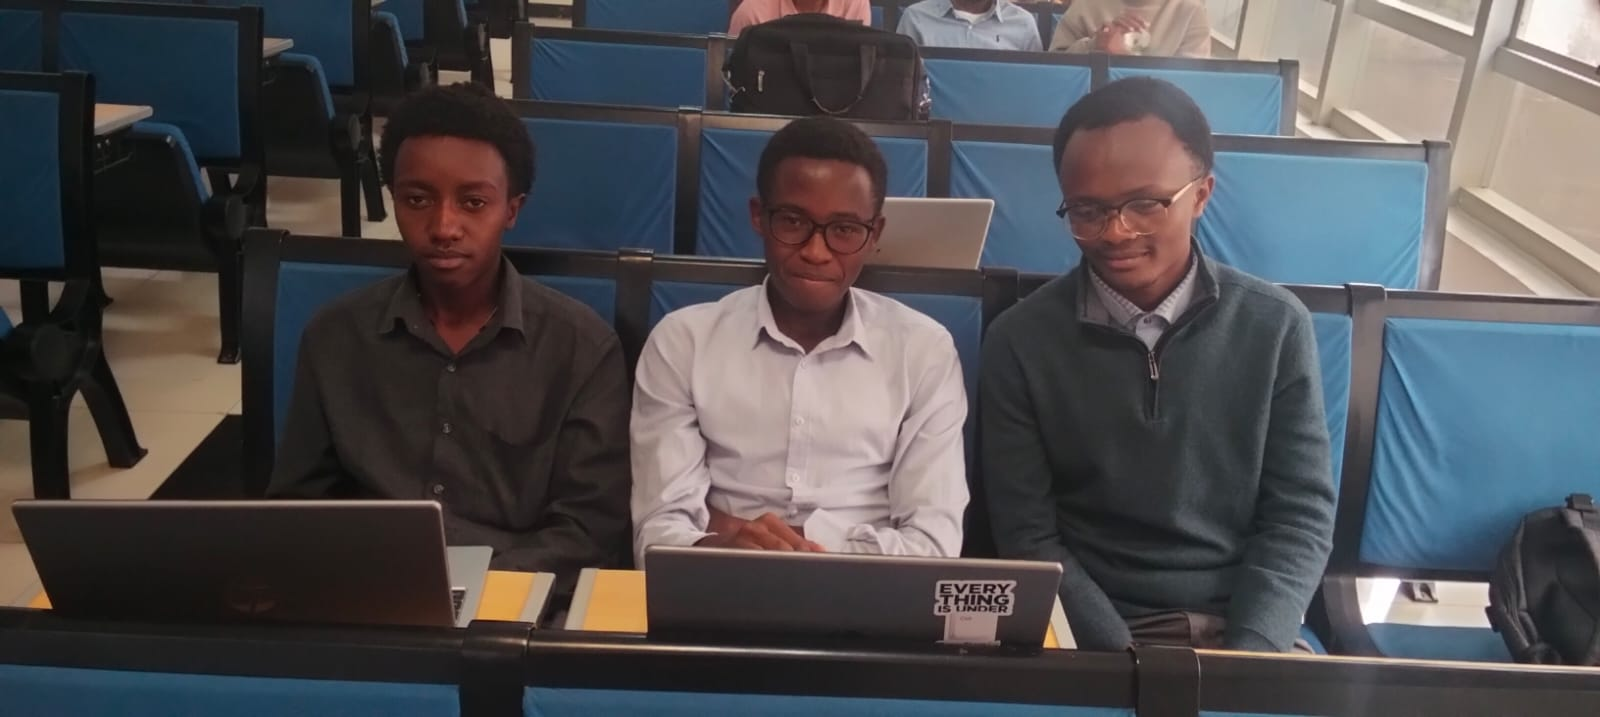